# Pregunta 3: fauna CCT20

Este notebook carga auditorías y resultados reales desde la salida de fauna. Las tablas científicas se muestran cuando termina su evaluación real; cada revisión humana pendiente conserva su estado explícito. La prueba pequeña (smoke) se identifica por separado y no aporta cifras al informe.


## Protocolo v6

YOLOv8s preentrenado, 14 clases animales, semilla 42, resolución 640, batch 16, hasta 50 épocas y paciencia 10. AdamW: tasa inicial 3e-4 y weight decay 1e-4. Se conservan los 1.000 fondos oficiales adicionales de v2 y todos los holdouts. V5 corrige la tercera caja de una foto de train según el recuadro rojo proporcionado por el revisor; conserva las otras dos cajas. Conserva las 89 aprobaciones sin exigir notas por fotografía, conforme a la confirmación humana registrada. Compose v6 selecciona configs/wildlife_v6.toml. V6 conserva los píxeles y las etiquetas aprobadas de V5: para JPEG con espacios tras el marcador final, genera una copia sin esos espacios y verifica igualdad exacta de los píxeles decodificados. El comprobador real de Ultralytics valida todas las imágenes y cajas antes de entrenar. cis_val depurado selecciona best.pt. El usuario definió usar el detector existente de Ultralytics y ajustarlo con CCT20. Esa decisión queda en receipts/architecture-review.json, junto con la revisión completa de las 90 fotos. Las tablas y mapas científicos se generan a partir de la ejecución real.


In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import HTML, Image, display
from neural_exam.config import load_settings
from neural_exam.common.io import read_json
from neural_exam.common.locking import execution_lock
from neural_exam.wildlife.data import prepare
from neural_exam.wildlife.review import label_review_status, prepare_label_review
from neural_exam.reporting import prepare_report_assets

RUN_PREPARE = False
RUN_TRAINING = False
RESUME = False
GENERATE_REPORT_ASSETS = False
settings = load_settings()
output = settings.output_root / 'wildlife'
os.environ.setdefault('YOLO_OFFLINE', 'true')
os.environ.setdefault('YOLO_AUTOINSTALL', 'false')
Path(os.environ.setdefault('YOLO_CONFIG_DIR', str(settings.output_root / 'cache/ultralytics'))).mkdir(parents=True, exist_ok=True)

def show_json(path):
    if path.exists():
        display(read_json(path))
    else:
        print(f'Pendiente: {path.name}')

def show_figure(path, width=900):
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f'Figura pendiente: {path.name}')


## Entorno, CUDA y reanudación

Las constancias siguientes provienen de las comprobaciones explícitas. Esta celda no inicia operaciones GPU. La interrupción sintética v3 verifica época, estados del optimizador y paciencia mediante un archivo ligado al hash de last.pt; no afirma equivalencia bit a bit ni rendimiento científico.


In [2]:
for path in [settings.output_root / 'receipts/doctor_gpu.json', settings.output_root / 'receipts/amp.json', settings.output_root / 'resume-check/passed.json']:
    show_json(path)


{'dependencies': {'torch': '2.10.0+cu128',
  'torchvision': '0.25.0+cu128',
  'ultralytics': '8.4.21',
  'pydicom': '3.0.1',
  'rasterio': '1.4.3',
  'scikit-learn': '1.9.1'},
 'locations': {'metadata_root': '/workspace/data',
  'mri_root': '/datasets',
  'flood_root': '/datasets/Sen1Floods11',
  'wildlife_root': '/datasets/cct-annotations',
  'output_root': '/outputs'},
 'data_directories_exist': {'metadata_root': True,
  'mri_root': True,
  'flood_root': False,
  'wildlife_root': True},
 'gpu_check': {'name': 'NVIDIA GeForce RTX 5090',
  'capability': [12, 0],
  'compiled_architectures': ['sm_70',
   'sm_75',
   'sm_80',
   'sm_86',
   'sm_90',
   'sm_100',
   'sm_120'],
  'gradient_finite': True,
  'nms_kept': [0]},
 'wildlife_roots': {'images': '/datasets/cct-images',
  'annotations': '/datasets/cct-annotations'},
 'pretrained_weights_available': {'resnet50-11ad3fa6.pth': False,
  'yolov8s.pt': True,
  'yolo26n.pt': True},
 'amp_check': {'status': 'passed',
  'auxiliary': 'yolo26n.

{'status': 'passed',
 'auxiliary': 'yolo26n.pt',
 'detector': 'yolov8s.pt',
 'finite': True,
 'fp32_amp_close': True,
 'messages': ['\x1b\x1bAMP: \x1brunning Automatic Mixed Precision (AMP) checks...',
  '\x1b\x1bAMP: \x1bchecks passed ✅']}

Pendiente: passed.json


## Integridad y particiones

Se decodifican las imágenes, se registra SHA-256 y se comprueban dimensiones y aspecto respecto a metadatos originales. Las cajas se normalizan con las dimensiones originales. Los JPG se enlazan en un volumen Linux; las imágenes de origen permanecen en solo lectura. Se excluyen animales sin cajas completas y vehículos sin animales. Solo empty explícito genera etiquetas vacías. El train ECCV oficial no contiene empty y todas las fotos vacías de sus diez cámaras estaban reservadas. La ampliación toma 125 secuencias independientes por cada una de ocho cámaras del train de la colección completa, con selección basada en metadatos. No modifica los holdouts. Los negativos tienen resolución original y proceden de cámaras sin positivos añadidos: ambas diferencias deben declararse al interpretar los resultados.


In [3]:
manifest = None
if RUN_PREPARE:
    with execution_lock(settings.output_root):
        manifest = prepare(settings)
        prepare_label_review(manifest, output, settings.training['seed'])
elif (output / 'manifest.json').exists():
    manifest = read_json(output / 'manifest.json')
else:
    print('Preparación pendiente.')

if manifest:
    display({'identity': manifest['identity'], 'bbox_units': manifest['bbox_units'], **manifest['integrity']})
    display(pd.DataFrame([{'split': split, 'images': row['images'], 'backgrounds': row['backgrounds'], 'cameras': len(row['cameras']), 'sequences': row['sequences']} for split, row in manifest['split_summary'].items()]))
    display(pd.DataFrame(list(manifest['sequence_overlaps'].items()), columns=['partition_pair', 'shared_sequences']))
    display(pd.DataFrame(manifest['class_map']))


{'identity': '7a2698cefc83dd3f3959e3cb3264bd7504cf295465fbaf179dcb1e5308d4ce82',
 'bbox_units': 'pixels',
 'referenced_images': 58864,
 'unreferenced_files': 0,
 'fully_decoded': True,
 'cached_by_size_mtime': True}

,split,images,backgrounds,cameras,sequences
0,train,12399,1000,18,5733
1,val,2543,995,10,980
2,cis_test,13073,1180,10,5378
3,trans_val,1592,61,1,589
4,trans_test,18647,1778,9,7438


,partition_pair,shared_sequences
0,train:val,0
1,train:cis_test,0
2,train:trans_val,0
3,train:trans_test,0
4,val:cis_test,0
5,val:trans_val,0
6,val:trans_test,0
7,cis_test:trans_val,0
8,cis_test:trans_test,0
9,trans_val:trans_test,0


,source_id,class_id,name
0,1,0,opossum
1,3,1,raccoon
2,5,2,squirrel
3,6,3,bobcat
4,7,4,skunk
5,8,5,dog
6,9,6,coyote
7,10,7,rabbit
8,11,8,bird
9,16,9,cat


,split,reason,images
0,cis_test,incomplete_animal_boxes,1951
1,cis_test,invalid_bbox,12
2,cis_test,no_animal_box_or_explicit_empty,791
3,train,incomplete_animal_boxes,1454
4,train,invalid_bbox,32
5,train,no_animal_box_or_explicit_empty,668
6,trans_test,incomplete_animal_boxes,3464
7,trans_test,invalid_bbox,51
8,trans_test,no_animal_box_or_explicit_empty,1113
9,trans_val,incomplete_animal_boxes,131


,species,training_boxes
0,opossum,2514
1,raccoon,1024
2,squirrel,1036
3,bobcat,682
4,skunk,214
5,dog,764
6,coyote,1368
7,rabbit,2266
8,bird,556
9,cat,1168


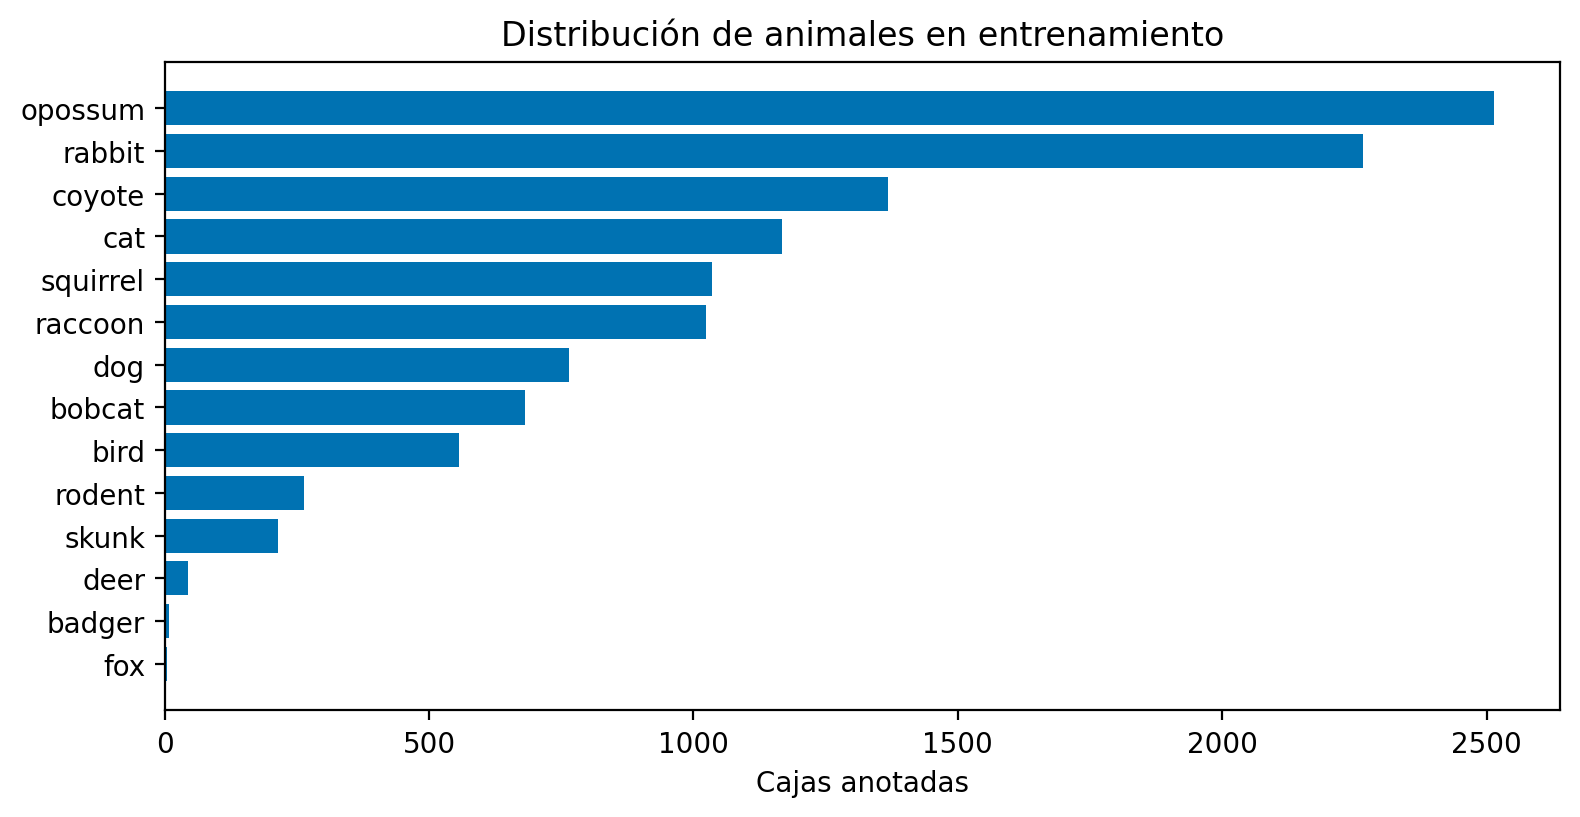

In [4]:
if manifest:
    exclusions = pd.DataFrame(manifest['exclusions'])
    if not exclusions.empty:
        display(exclusions.groupby(['split', 'reason']).size().rename('images').reset_index())
    display(pd.DataFrame(list(manifest['train_class_boxes'].items()), columns=['species', 'training_boxes']))
    show_figure(output / 'class_balance.png')


## Revisión humana antes de entrenar

V5 conserva las 89 decisiones de Miguel cuyos objetivos de revisión no cambiaron. Su confirmación global queda registrada en receipts/human-label-confirmation.json. El CSV humano contiene 90 fotografías aprobadas por Miguel, incluida 596bdb10-23d2-11e8-a6a3-ec086b02610b tras convertir su tercera caja desde el recuadro rojo. La aprobación original y el hash del CSV constan en la salida preservada v5, receipts/human-label-review-completion.json. V6 conserva las 90 revisiones auténticas mediante review_migration.json: las fotografías y cajas permanecen idénticas. La referencia y su hash quedan archivados en inputs/user-reference/ave.png y configs/wildlife_label_corrections_v6.json. La revisión anterior queda en parent_label_review.csv. Las filas correctas requieren aprobación y evaluador; las notas visuales son opcionales. La observación humana inicial se conserva en el CSV histórico de v3. Guardar el CSV exportado en wildlife/label_review.csv; al repetir el comando se actualiza la galería desde ese archivo. La decisión de usar YOLOv8s existente está registrada en receipts/architecture-review.json como instrucción directa del usuario. No se asignan juicios ni autoría de forma automática.


{'status': 'reviewed',
 'images': 90,
 'counts': {'reviewed': 90},
 'missing_visual_evidence': 90,
 'evidence_required': False}

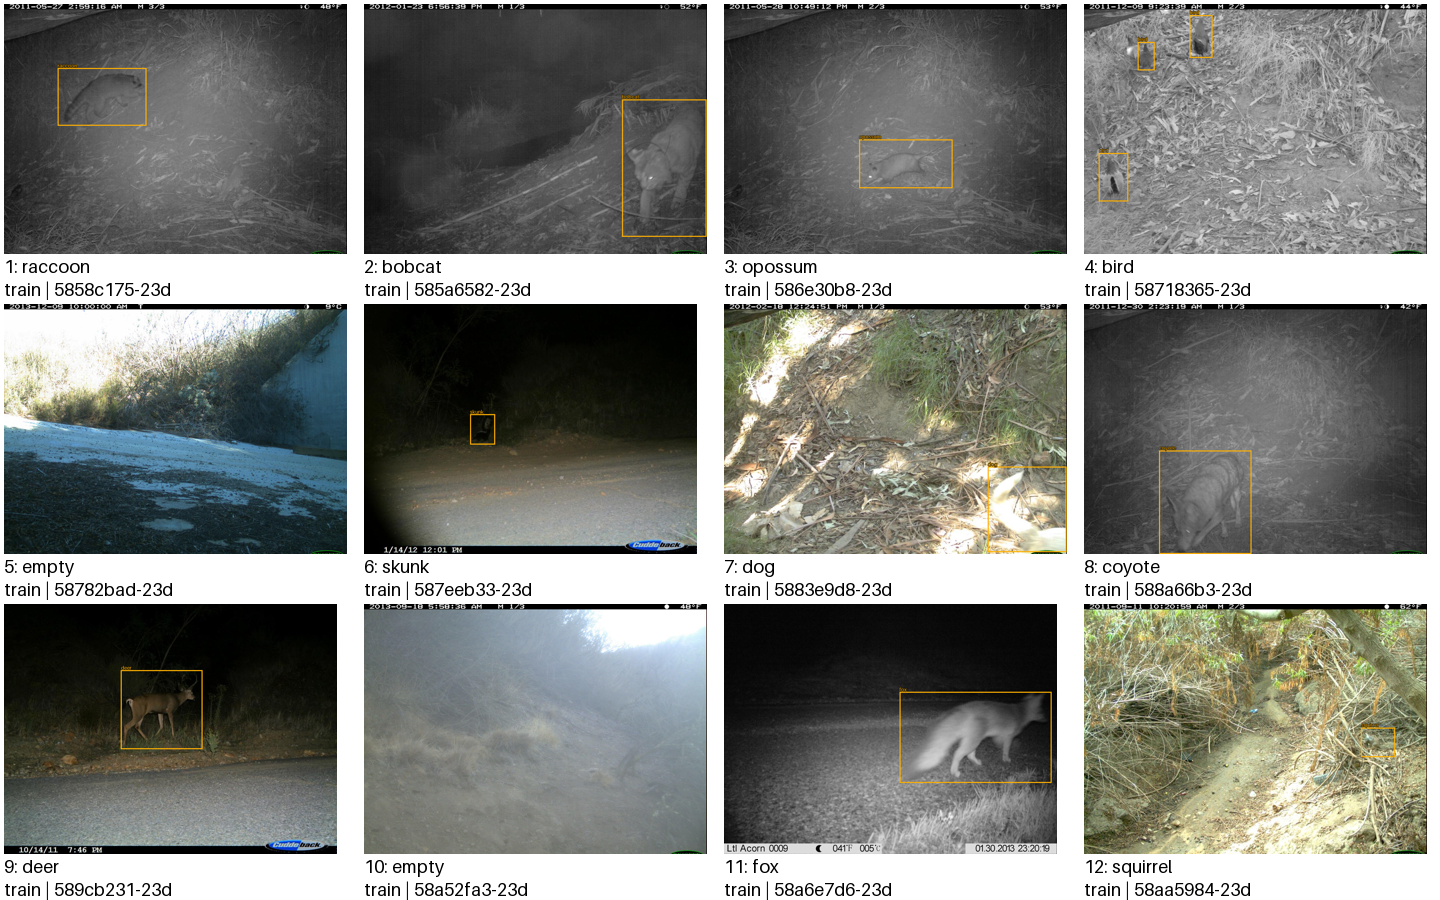

{'status': 'reviewed',
 'receipt': '/outputs/receipts/architecture-review.json',
 'decision': {'recorded_at_utc': '2026-10-05T20:30:09.0194777Z',
  'reviewed': True,
  'decision': 'pretrained_detector_permitted',
  'reviewer': 'User (direct instruction in this conversation)',
  'evidence': 'The user explicitly directed this project to use existing YOLO rather than implement a separate YOLO. Question 3 requests an adjusted YOLO model. This records the user-directed project scope and does not represent confirmation from the teacher.',
  'source': 'direct_user_instruction',
  'user_statement': 'lo que debemos es usar el YOLO, no crear nuestro propio YOLO',
  'permission_authority': 'project user',
  'teacher_confirmation_provided': False,
  'model': 'Ultralytics YOLOv8s',
  'workflow': 'Fine-tune the existing detector on the prepared 14-class CCT20 dataset; retain original data preparation, evaluation and ecological postprocessing.',
  'own_detector_components_claimed': False}}

{'parent_manifest': 'b8a8a0fccba36e5bdbc214fa9f9987d3b413282e6a2c662ccbe41a30f9f92d5a',
 'current_manifest': '7a2698cefc83dd3f3959e3cb3264bd7504cf295465fbaf179dcb1e5308d4ce82',
 'parent_csv_sha256': '6575055088727b483c1f36197d9b83a294194043087571bff64c19149b8fc447',
 'unchanged_rows_carried': 90,
 'changed_images_requiring_review': []}

{'method': 'remove whitespace after an existing JPEG end marker; no re-encoding',
 'eligible_sources_checked': 48254,
 'canonical_copies': 1000,
 'source_photographs_modified': False,
 'all_copied_pixels_verified_identical': True,
 'copy_registry_identity': '44ad4bb3c4016cfff3949675bc48e9b7ac6bb54db7e3097ec086b35eaf31d7f5'}

{'status': 'passed',
 'manifest_identity': '7a2698cefc83dd3f3959e3cb3264bd7504cf295465fbaf179dcb1e5308d4ce82',
 'ultralytics_version': '8.4.21',
 'verifier': 'ultralytics.data.utils.verify_image_label',
 'splits': {'train': {'expected_images': 12399,
   'accepted_images': 12399,
   'backgrounds': 1000,
   'boxes': 11913},
  'val': {'expected_images': 2543,
   'accepted_images': 2543,
   'backgrounds': 995,
   'boxes': 1644},
  'cis_test': {'expected_images': 13073,
   'accepted_images': 13073,
   'backgrounds': 1180,
   'boxes': 12461},
  'trans_val': {'expected_images': 1592,
   'accepted_images': 1592,
   'backgrounds': 61,
   'boxes': 1670},
  'trans_test': {'expected_images': 18647,
   'accepted_images': 18647,
   'backgrounds': 1778,
   'boxes': 17620}},
 'problem_count': 0,
 'problems': []}

In [5]:
if (output / 'label_review.csv').exists():
    display(label_review_status(output / 'label_review.csv', require_evidence=settings.wildlife.get('require_label_evidence', False)))
    display(HTML('<a href="/files/wildlife/label_review.html" target="_blank">Abrir galería completa de etiquetas en Jupyter</a>'))
    show_figure(output / 'label_contact_01.png', width=1100)
else:
    print('Galería pendiente: ejecutar review-labels.')
from neural_exam.wildlife.review import architecture_review_status
display(architecture_review_status(settings.output_root / 'receipts/architecture-review.json'))
show_json(output / 'review_migration.json')
display(manifest.get('jpeg_materialization', {})) if manifest else None
show_json(settings.output_root / 'receipts/yolo-loader-verification.json')


## Smoke aislado

Una época, muestreo estratificado de train/cis_val, con al menos un caso por clase disponible y algunos fondos. No se predice sobre cis_test ni trans_test. Esta evidencia sólo valida la ejecución y no mide el rendimiento científico final.


In [6]:
show_json(settings.output_root / 'smoke/execution_summary.json')
smoke_path = settings.output_root / 'smoke/wildlife/smoke_validation.json'
if smoke_path.exists():
    smoke = read_json(smoke_path)
    display({'scientific_run': smoke['scientific_run'], 'test_partitions_used': smoke['test_partitions_used'], 'eligible_validation_objects': smoke['metrics']['eligible_objects']})
else:
    print('Smoke pendiente.')


Pendiente: execution_summary.json
Smoke pendiente.


## Entrenamiento completo

Activar RUN_TRAINING únicamente tras la revisión de etiquetas. El comando documentado también ejecuta evaluación, monitoreo y mapas. No iniciar otro entrenamiento simultáneo. RESUME recupera last.pt o reutiliza best.pt cuando el entrenamiento ya terminó.


La ejecución completa no se inicia desde este notebook; se muestran resultados guardados cuando existen.


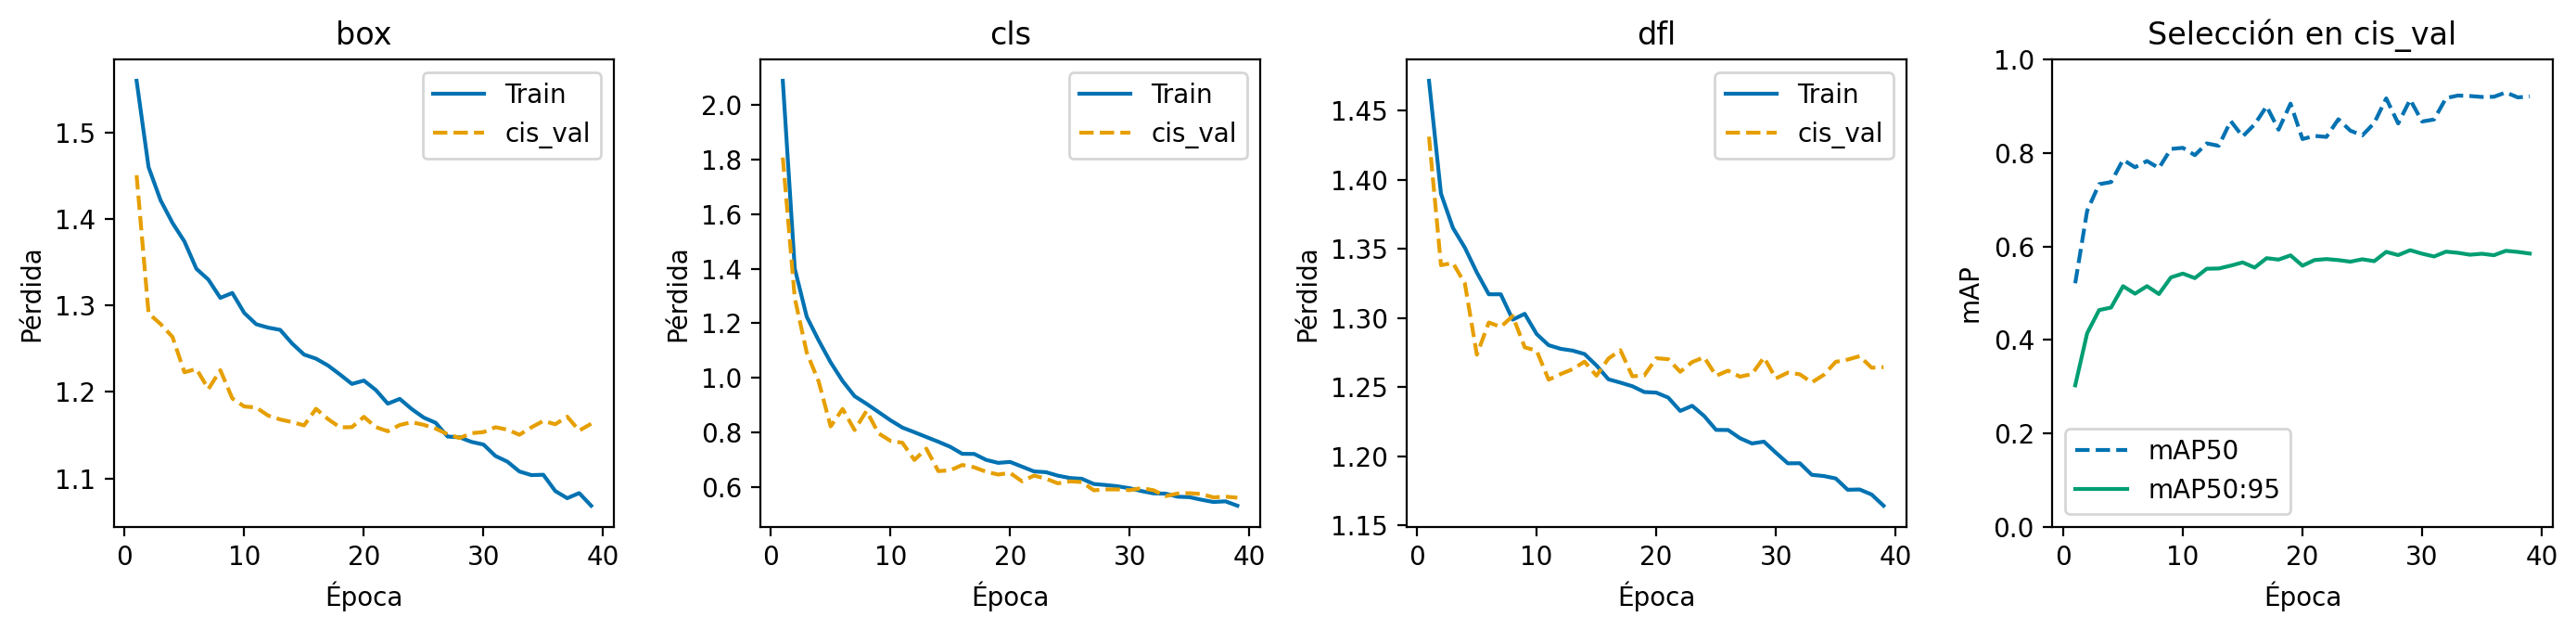

In [7]:
if RUN_TRAINING:
    from neural_exam.wildlife.pipeline import run
    with execution_lock(settings.output_root):
        display(run(settings, resume=RESUME, quick=False, manifest=manifest))
else:
    print('La ejecución completa no se inicia desde este notebook; se muestran resultados guardados cuando existen.')
show_figure(output / 'training_curves.png')


## Cámaras vistas y nuevas

AP COCO a 101 puntos de recall, IoU 0.50:0.95, confianza 0.001, NMS 0.7 y máximo 300 detecciones. AP de una categoría sin referencia queda indefinida. Se conserva la brecha global y se agrega una comparación sobre categorías con soporte en ambos tests. Los intervalos percentiles del 95 % remuestrean secuencias completas con 200 réplicas, semilla 42 y checkpoint fijo. No miden variación entre semillas ni generalización a regiones nuevas.

En V6 quedaron completos los ocho grupos de intervalos, con 200 réplicas cada uno. Tras un límite de memoria, la recuperación usó un proceso nuevo por grupo, conservando la función original, semilla, predicciones y checkpoint; no repitió el entrenamiento.


In [8]:
if (output / 'experiments.csv').exists():
    display(pd.read_csv(output / 'experiments.csv'))
else:
    print('Evaluación científica pendiente.')
for split in ['cis_test', 'trans_test']:
    path = output / split / 'metrics.json'
    if path.exists():
        metrics = read_json(path)
        display({'split': split, 'map50': metrics['map50'], 'map50_95': metrics['map50_95'], 'protocol': metrics['protocol']})
        display(pd.DataFrame(metrics['per_species']))
show_json(output / 'generalization.json')
show_json(output / 'uncertainty.json')


,experiment,cis_map50,trans_map50,cis_map50_95,trans_map50_95,geographic_gap
0,yolov8s,0.687752,0.423057,0.435753,0.262486,0.173267


{'split': 'cis_test',
 'map50': 0.6877518839162803,
 'map50_95': 0.435752672103409,
 'protocol': {'checkpoint_sha256': 'b2a47c3b0b22d927c5fa976e6fecf82465e22bc509fae1747fb8a20ff634c85f',
  'conf': 0.001,
  'nms_iou': 0.7,
  'max_detections': 300,
  'categories_evaluated': 14}}

,species,support,map50,map50_95
0,opossum,4008,0.884361,0.493221
1,raccoon,980,0.897040,0.591715
2,squirrel,510,0.703707,0.369596
3,bobcat,772,0.856096,0.608422
4,skunk,161,0.935515,0.617486
5,dog,723,0.693182,0.485843
6,coyote,1180,0.903527,0.690057
7,rabbit,1556,0.887354,0.553441
8,bird,752,0.643527,0.333379
9,cat,1528,0.874851,0.586577


{'split': 'trans_test',
 'map50': 0.4230570686004039,
 'map50_95': 0.2624855373660651,
 'protocol': {'checkpoint_sha256': 'b2a47c3b0b22d927c5fa976e6fecf82465e22bc509fae1747fb8a20ff634c85f',
  'conf': 0.001,
  'nms_iou': 0.7,
  'max_detections': 300,
  'categories_evaluated': 13}}

,species,support,map50,map50_95
0,opossum,4659,0.882559,0.459047
1,raccoon,4769,0.754918,0.495901
2,squirrel,777,0.364415,0.195702
3,bobcat,1974,0.626764,0.417603
4,skunk,273,0.440199,0.284029
5,dog,958,0.737688,0.499430
6,coyote,1901,0.674567,0.478777
7,rabbit,722,0.591207,0.299446
8,bird,179,0.068736,0.038252
9,cat,1366,0.282927,0.184236


{'cis_map50': 0.6877518839162803,
 'trans_map50': 0.4230570686004039,
 'cis_map50_95': 0.435752672103409,
 'trans_map50_95': 0.2624855373660651,
 'gap': 0.1732671347373439,
 'gap_map50': 0.2646948153158764,
 'common_categories': ['opossum',
  'raccoon',
  'squirrel',
  'bobcat',
  'skunk',
  'dog',
  'coyote',
  'rabbit',
  'bird',
  'cat',
  'badger',
  'fox',
  'rodent'],
 'common_category_scores': {'cis_test': {'map50': 0.7010696463970321,
   'map50_95': 0.4432496262101425},
  'trans_test': {'map50': 0.42305706860040393,
   'map50_95': 0.2624855373660651}}}

{'signature': '7c62c83a18330b4adc47585bbb56b7ff5f76939ce9420debe0f79fcd865fd4d4',
 'global': {'cis_test': {'method': 'percentile sequence-cluster bootstrap; fixed checkpoint; not between-seed uncertainty',
   'replicates': 200,
   'seed': 42,
   'clusters': 5378,
   'confidence_level': 0.95,
   'intervals': {'map50': {'lower': 0.6778651232729754,
     'upper': 0.751108574184408,
     'defined_replicates': 200},
    'map50_95': {'lower': 0.4287868308123333,
     'upper': 0.47854256699002323,
     'defined_replicates': 200}}},
  'trans_test': {'method': 'percentile sequence-cluster bootstrap; fixed checkpoint; not between-seed uncertainty',
   'replicates': 200,
   'seed': 42,
   'clusters': 7438,
   'confidence_level': 0.95,
   'intervals': {'map50': {'lower': 0.4113553424073453,
     'upper': 0.4811198618631211,
     'defined_replicates': 200},
    'map50_95': {'lower': 0.2537857738933228,
     'upper': 0.3022630787556298,
     'defined_replicates': 200}}}},
 'size': {'cis_test': {'sma

## Tamaño relativo y oclusión

Tamaño: pequeño <1 %, mediano 1–5 %, grande >5 % del área de la foto, en ambos tests. Oclusión v2: cohorte completa de objetos elegibles de trans_test, al menos 30 por nivel y ningún objeto sin revisión. Baja >75 % visible; media 25–75 %; alta <25 %. Visibilidad incierta o truncamiento: ambiguous, con evidencia y evaluador. Área y truncamiento no sustituyen oclusión. Los otros niveles y ambiguos son regiones crowd ignoradas en la comparación por grupo. La cobertura parcial conserva estado pendiente. La galería usa las imágenes existentes y superpone la caja del objeto; no duplica miles de fotografías.


In [9]:
path = output / 'robustness.json'
if path.exists():
    robustness = read_json(path)
    for split, groups in robustness['size_by_split'].items():
        display(pd.DataFrame([{'split': split, 'group': group, 'objects': score['eligible_objects'], 'map50': score['map50'], 'map50_95': score['map50_95']} for group, score in groups.items()]))
    display({'occlusion_status': robustness['occlusion_status']})
    display(pd.DataFrame([{'level': level, 'reviewed_objects': score['reviewed_objects'], 'meets_minimum': score['meets_minimum'], 'map50': score['map50'], 'map50_95': score['map50_95']} for level, score in robustness['occlusion'].items()]))
else:
    print('Robustez pendiente de evaluación y revisión humana.')


,split,group,objects,map50,map50_95
0,cis_test,small_lt_1pct,1149,0.563096,0.279170
1,cis_test,medium_1_to_5pct,8925,0.751626,0.468338
2,cis_test,large_gt_5pct,2387,0.758329,0.548001


,split,group,objects,map50,map50_95
0,trans_test,small_lt_1pct,1922,0.321596,0.161862
1,trans_test,medium_1_to_5pct,12169,0.527245,0.322044
2,trans_test,large_gt_5pct,3529,0.402423,0.286956


{'occlusion_status': 'manual_review_pending'}

,level,reviewed_objects,meets_minimum,map50,map50_95
0,low,0,False,None,None
1,medium,0,False,None,None
2,high,0,False,None,None


## Doce casos Grad-CAM

Seis por test: detección correcta a IoU ≥0.5, omisión/clase incorrecta y falsos positivos en fondo, cuando estén disponibles. La selección contrasta soporte raro/frecuente y horarios diurno/nocturno, con alternativas deterministas si falta un tipo de caso. La hora de captura es una aproximación de iluminación que se inspecciona visualmente. Se explica una propuesta y clase antes de NMS en la capa 9. Los mapas no prueban memorización causal del fondo.

La revisión de V6 registra tres mapas planos con rango [0, 0]: cis_test_3, trans_test_3 y trans_test_5. No ofrecen explicación espacial positiva. Varias fotos rotuladas day por metadatos son oscuras y de apariencia infrarroja; ese rótulo no mide iluminación real. Los doce casos originales y la técnica congelada se conservan.


,split,image_id,camera_id,case,class,capture_period,training_support,score
0,cis_test,59c99f45-23d2-11e8-a6a3-ec086b02610b,43,false_positive,skunk,day,214,0.420285
1,cis_test,58782b43-23d2-11e8-a6a3-ec086b02610b,120,false_positive,opossum,night,2514,0.407437
2,cis_test,5a296348-23d2-11e8-a6a3-ec086b02610b,61,missed_or_wrong_class,deer,day,44,0.000080
3,cis_test,5858c152-23d2-11e8-a6a3-ec086b02610b,108,missed_or_wrong_class,opossum,night,2514,0.087778
4,cis_test,5975160a-23d2-11e8-a6a3-ec086b02610b,61,detected_iou50,deer,day,44,0.144899
5,cis_test,585a6381-23d2-11e8-a6a3-ec086b02610b,88,detected_iou50,opossum,night,2514,0.807455
6,trans_test,596d6622-23d2-11e8-a6a3-ec086b02610b,46,false_positive,skunk,day,214,0.689806
7,trans_test,58c97c14-23d2-11e8-a6a3-ec086b02610b,78,false_positive,opossum,night,2514,0.676951
8,trans_test,59b61685-23d2-11e8-a6a3-ec086b02610b,28,missed_or_wrong_class,skunk,day,214,0.095736
9,trans_test,5858bf75-23d2-11e8-a6a3-ec086b02610b,78,missed_or_wrong_class,opossum,night,2514,0.272223


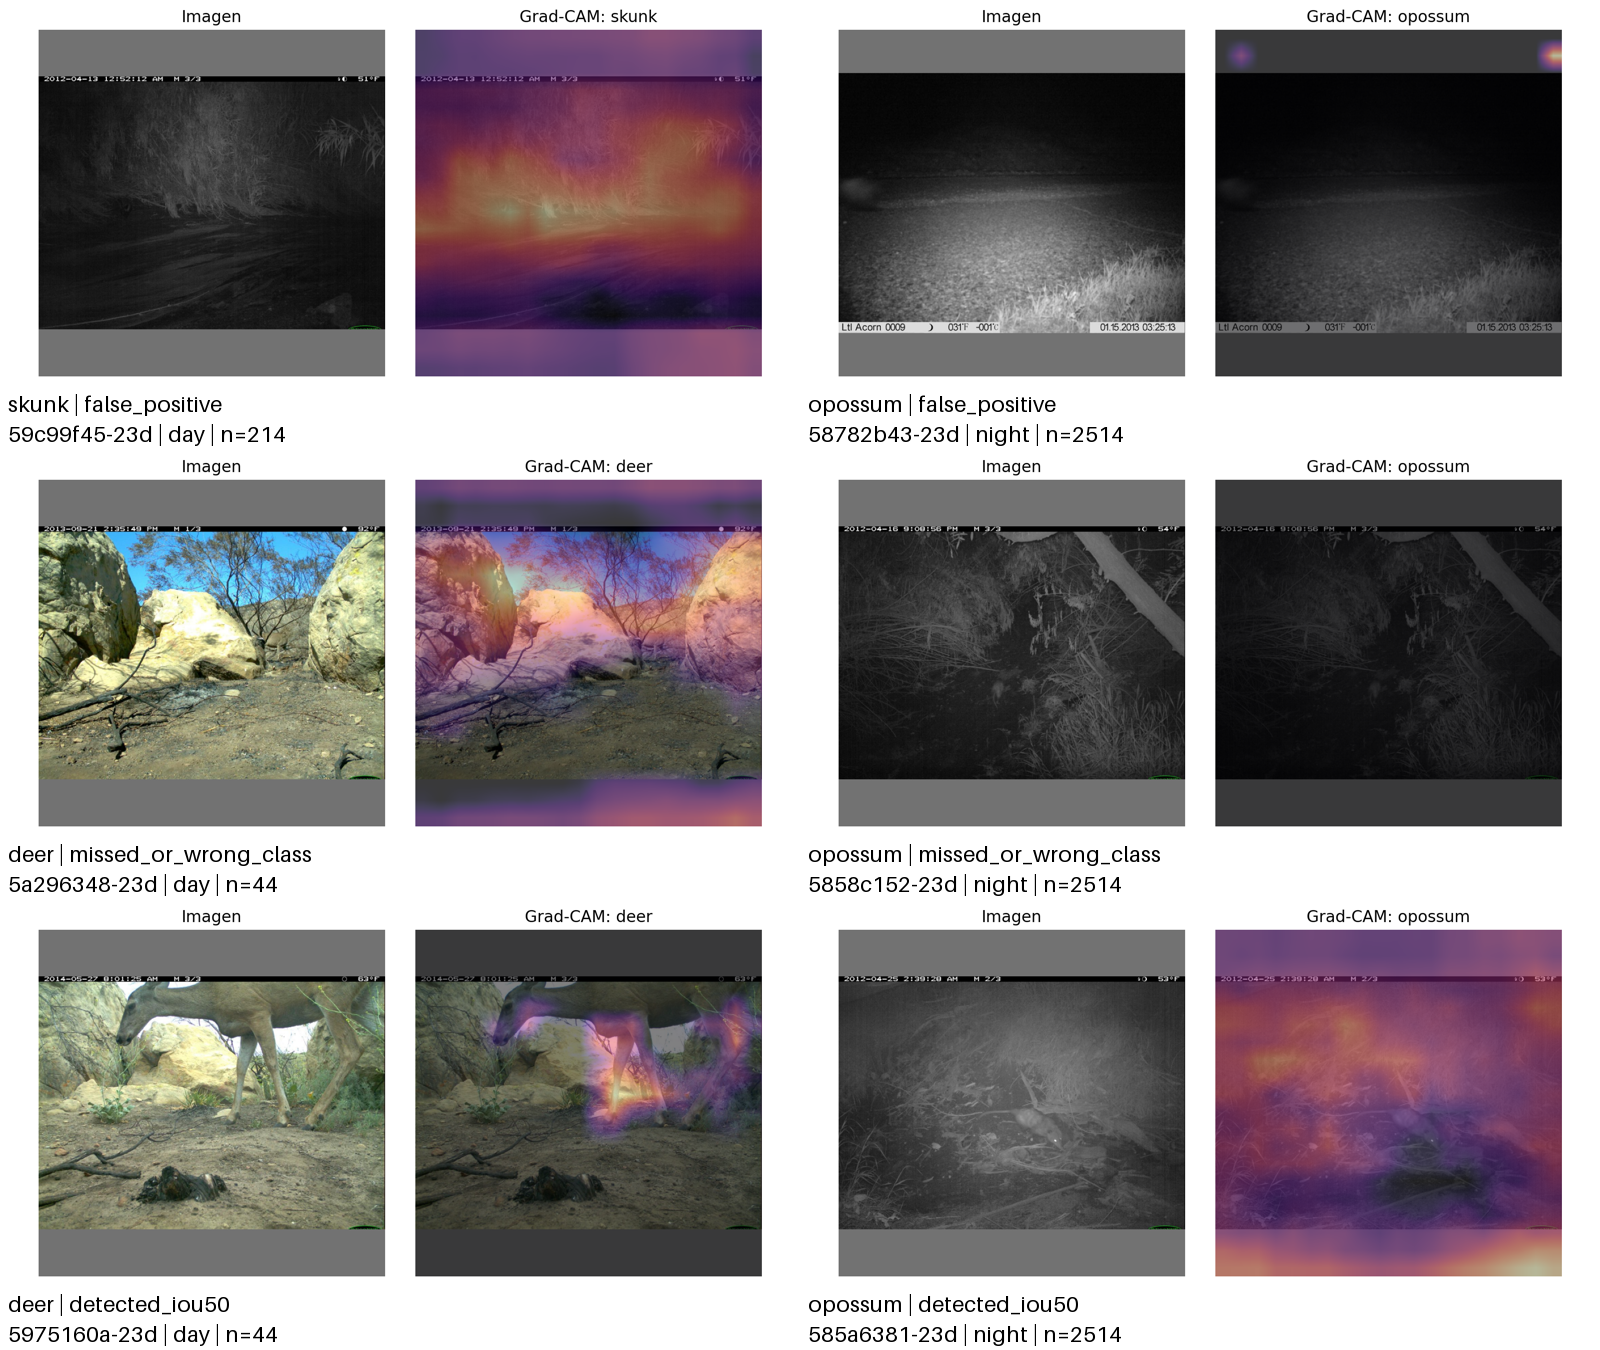

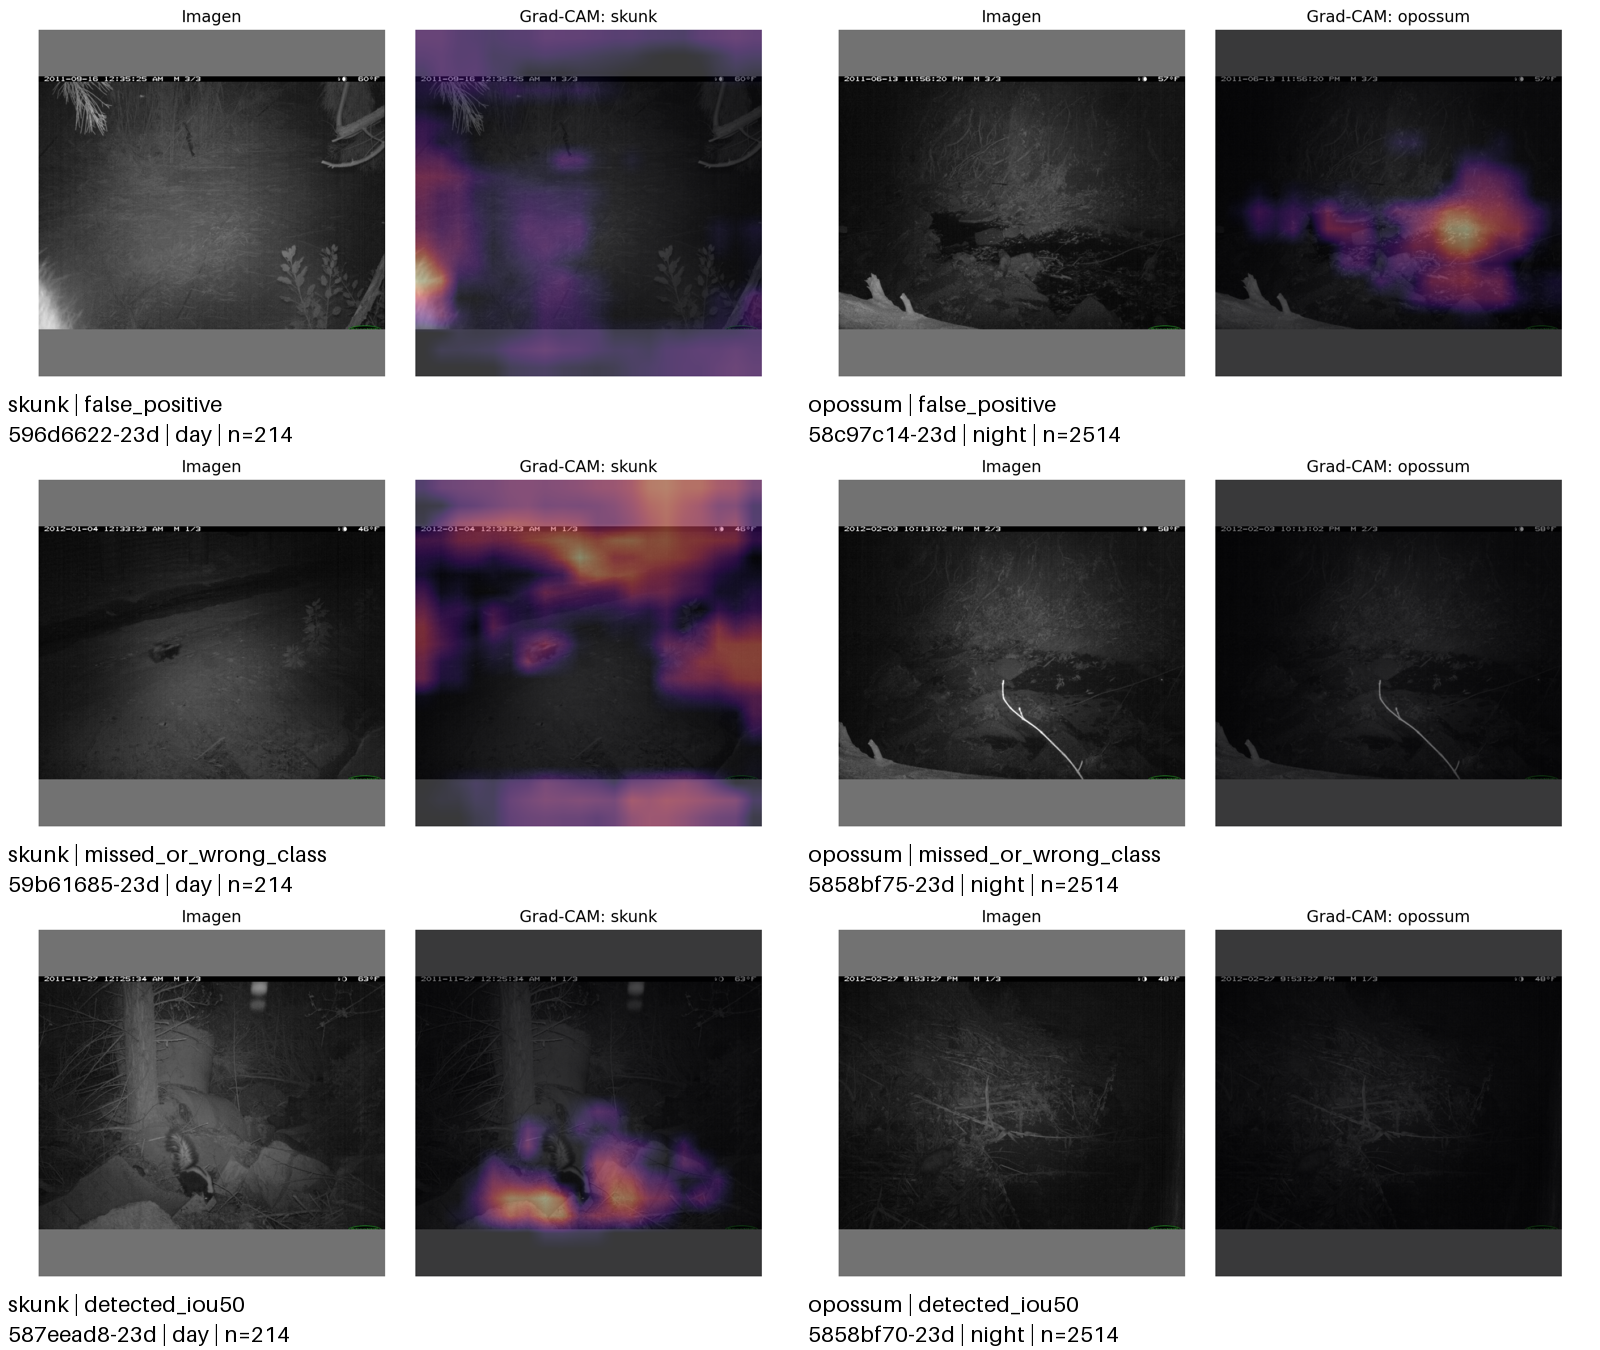

In [10]:
if (output / 'cam_cases.json').exists():
    display(pd.DataFrame(read_json(output / 'cam_cases.json'))[['split', 'image_id', 'camera_id', 'case', 'class', 'capture_period', 'training_support', 'score']])
for split in ['cis_test', 'trans_test']:
    show_figure(output / f'cam_{split}_grid.png', width=1100)


## Demostración de actividad ecológica

Una cámara nueva elegida por ID, con todos sus fotogramas oficiales, incluidos los excluidos del análisis de cajas. Se requiere fecha de captura válida y una ráfaga completa de al menos dos fotos. Confianza 0.25. Las detecciones no son individuos; las fotografías por especie se cuentan una vez aunque existan varias cajas. Las fechas sin zona no se convierten a Lima.

La demostración V6 contiene 1.853 fotografías de la cámara 7 en 211 fechas: 1.420 con detecciones y once categorías. La tasa predicha de fotos vacías es 23,37 %. La ráfaga mostrada tiene tres fotogramas; no es un conteo de individuos.


In [11]:
path = output / 'activity.json'
if path.exists():
    activity = read_json(path)
    display({key: activity[key] for key in ['camera_id', 'sequence_id', 'cohort', 'timezone', 'confidence', 'interpretation']})
    display(pd.DataFrame(activity['camera_days']))
    display(pd.DataFrame(activity['species_days']))
    display(pd.DataFrame(activity['sequence_frames']))
else:
    print('Demostración con predicciones finales pendiente.')


{'camera_id': '7',
 'sequence_id': '6f06c47d-5567-11e8-b8ef-dca9047ef277',
 'cohort': 'all official trans_test frames of one predetermined camera; includes frames excluded from box evaluation',
 'timezone': 'capture timezone unspecified; no conversion',
 'confidence': 0.25,
 'interpretation': 'counts are detections and photographs, never unique individual animals'}

,camera_id,date,photos,photos_with_fauna,empty_photo_rate,distinct_species
0,7,2011-05-07,1,0,1.000000,0
1,7,2011-05-08,9,2,0.777778,1
2,7,2011-05-10,3,1,0.666667,1
3,7,2011-05-20,3,3,0.000000,1
4,7,2011-05-25,2,1,0.500000,1
...,...,...,...,...,...,...
206,7,2012-05-12,15,7,0.533333,1
207,7,2012-05-13,15,15,0.000000,2
208,7,2012-05-14,9,6,0.333333,1
209,7,2012-05-16,3,2,0.333333,1


,camera_id,date,species,detections,photos_with_species
0,7,2011-05-08,opossum,2,2
1,7,2011-05-10,coyote,1,1
2,7,2011-05-20,opossum,3,3
3,7,2011-05-25,coyote,1,1
4,7,2011-06-03,deer,1,1
...,...,...,...,...,...
314,7,2012-05-13,opossum,12,12
315,7,2012-05-13,squirrel,5,3
316,7,2012-05-14,opossum,6,6
317,7,2012-05-16,coyote,2,2


,image_id,camera_id,sequence_id,timestamp,frame_number,detections,species
0,597515c6-23d2-11e8-a6a3-ec086b02610b,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,2011-05-08 11:39:22,1,0,
1,5968c329-23d2-11e8-a6a3-ec086b02610b,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,2011-05-08 11:39:23,2,0,
2,59ef8e67-23d2-11e8-a6a3-ec086b02610b,7,6f06c47d-5567-11e8-b8ef-dca9047ef277,2011-05-08 11:39:24,3,1,opossum


## Informe y límites

Los activos se generan desde resultados completos con el mismo checkpoint. Antes del PDF final se requieren revisión humana de etiquetas y oclusión, los doce mapas, discusión sustentada en cifras, cinco autores reales y revisión editorial de 6–10 páginas. La evaluación de CCT20 no valida un despliegue en hábitats peruanos ni permite estimar población.

La ejecución V6 completó 39 épocas, seleccionó la época 29 y produjo el borrador de 10 páginas. La discusión incorpora métricas e intervalos reales y las limitaciones de los mapas. La revisión de etiquetas conserva 90 aprobaciones auténticas. La oclusión tiene 0/17.620 objetos con nivel registrado y la aprobación editorial humana sigue pendiente.


In [12]:
if GENERATE_REPORT_ASSETS:
    display(prepare_report_assets(settings, 'wildlife'))
show_json(settings.output_root / 'reports/wildlife/status.json')


{'status': 'assets_generated',
 'experiment_count': 1,
 'missing_figures': [],
 'editorial_review': 'pending',
 'source': '/outputs/wildlife/experiments.csv',
 'test_selected_baseline': False,
 'occlusion_status': 'manual_review_pending',
 'occlusion_coverage': {'total_objects': 17620,
  'reviewed_objects': 0,
  'ambiguous_objects': 0,
  'unreviewed_objects': 17620,
  'require_full': True},
 'label_review_status': 'reviewed',
 'checkpoint_sha256': 'b2a47c3b0b22d927c5fa976e6fecf82465e22bc509fae1747fb8a20ff634c85f',
 'cam_cases': 12}